In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigsh
from scipy.linalg import eigh
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

In [2]:
def gen_sbm(n, p, q):
    labels = np.array([1]*(n//2) + [-1]*(n//2))
    A = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):
            prob = p if labels[i] == labels[j] else q
            if np.random.rand() < prob:
                A[i, j] = A[j, i] = 1
    return A, labels

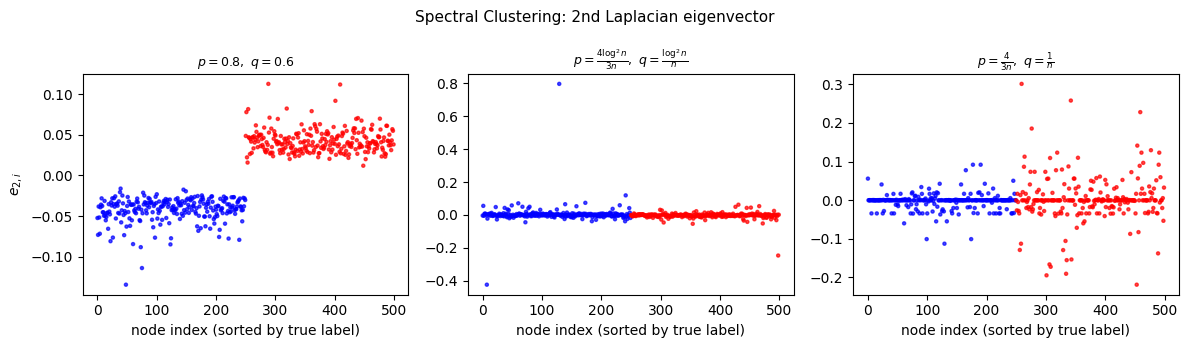

In [3]:
n = 500
log2n = np.log(n)**2
params = [
    (0.8, 0.6),
    (4*log2n/(3*n), log2n/n),
    (4/(3*n), 1/n)
]
titles = [r'$p=0.8,\ q=0.6$',
          r'$p=\frac{4\log^2 n}{3n},\ q=\frac{\log^2 n}{n}$',
          r'$p=\frac{4}{3n},\ q=\frac{1}{n}$']

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

e2_middle = None

for idx, ((p, q), title) in enumerate(zip(params, titles)):
    A, labels = gen_sbm(n, p, q)
    deg = A.sum(axis=1)
    D = np.diag(deg)
    L = D - A
    # get 2 smallest eigenvectors
    vals, vecs = eigh(L, subset_by_index=[0, 1])
    e2 = vecs[:, 1]
    if idx == 1:
        e2_middle = e2.copy()
    km = KMeans(n_clusters=2, n_init=10).fit(e2.reshape(-1, 1))
    pred = km.labels_
    ax = axes[idx]
    order = np.argsort(labels)
    ax.scatter(range(n), e2[order], c=labels[order], cmap='bwr', s=5, alpha=0.7)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('node index (sorted by true label)')
    if idx == 0:
        ax.set_ylabel(r'$e_{2,i}$')

fig.suptitle('Spectral Clustering: 2nd Laplacian eigenvector', fontsize=11)
plt.tight_layout()
plt.savefig('Figures/fig2a.pdf', bbox_inches='tight')
plt.show()

In [4]:
def gen_features(n, d, sigma):
    labels = np.array([1]*(n//2) + [-1]*(n//2))
    v = np.random.randn(d) / np.sqrt(d)
    u = v / np.linalg.norm(v)
    X = np.outer(labels, u) / np.sqrt(d)
    if sigma > 0:
        X += sigma * np.random.randn(n, d) / np.sqrt(d)
    return X, labels

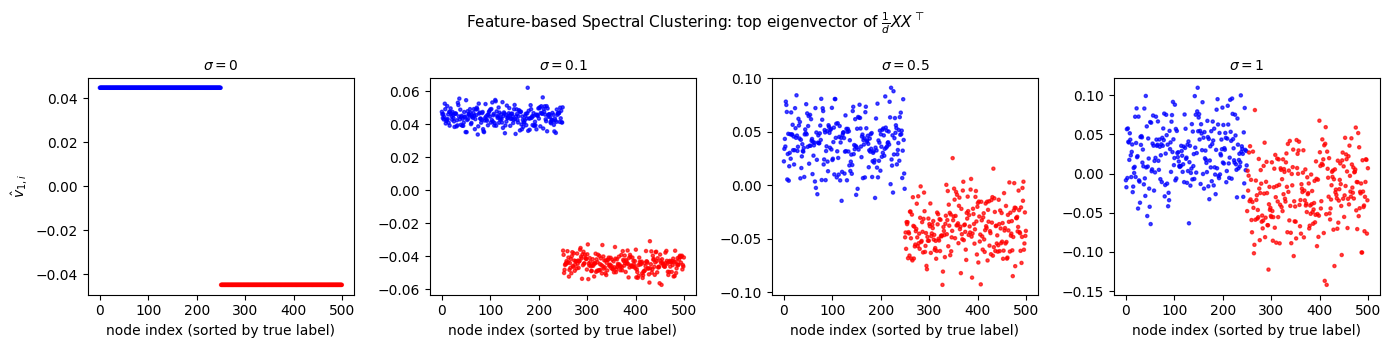

In [5]:
n, d = 500, 250
sigmas = [0, 0.1, 0.5, 1]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

vhat1_sigma05 = None
labels_feat = None

for idx, sigma in enumerate(sigmas):
    X, labels = gen_features(n, d, sigma)
    M = (X @ X.T) / d
    vals, vecs = eigh(M, subset_by_index=[n-1, n-1])
    vhat1 = vecs[:, 0]
    if sigma == 0.5:
        vhat1_sigma05 = vhat1.copy()
        labels_feat = labels.copy()
    km = KMeans(n_clusters=2, n_init=10).fit(vhat1.reshape(-1, 1))
    pred = km.labels_
    ax = axes[idx]
    order = np.argsort(labels)
    ax.scatter(range(n), vhat1[order], c=labels[order], cmap='bwr', s=5, alpha=0.7)
    ax.set_title(rf'$\sigma={sigma}$', fontsize=10)
    ax.set_xlabel('node index (sorted by true label)')
    if idx == 0:
        ax.set_ylabel(r'$\hat v_{1,i}$')

fig.suptitle(r'Feature-based Spectral Clustering: top eigenvector of $\frac{1}{d}XX^\top$', fontsize=11)
plt.tight_layout()
plt.savefig('Figures/fig2c.pdf', bbox_inches='tight')
plt.show()

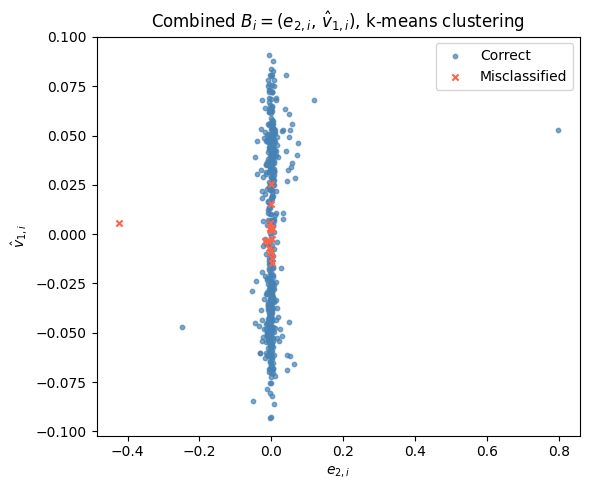

Accuracy: 0.968


In [6]:
# e2_middle from cell 3 (middle (p,q) case), vhat1_sigma05 from cell 5 (sigma=0.5)
B = np.column_stack([e2_middle, vhat1_sigma05])
km = KMeans(n_clusters=2, n_init=10).fit(B)
pred = km.labels_

# align predicted labels with true labels
true = (labels_feat + 1) // 2  # convert {-1,1} to {0,1}
acc1 = np.mean(pred == true)
acc2 = np.mean(pred == 1 - true)
aligned_pred = pred if acc1 >= acc2 else 1 - pred

fig, ax = plt.subplots(figsize=(6, 5))
correct = aligned_pred == true
ax.scatter(B[correct, 0], B[correct, 1], c='steelblue', s=10, alpha=0.7, label='Correct')
ax.scatter(B[~correct, 0], B[~correct, 1], c='tomato', s=20, marker='x', label='Misclassified')
ax.set_xlabel(r'$e_{2,i}$')
ax.set_ylabel(r'$\hat v_{1,i}$')
ax.set_title(r'Combined $B_i = (e_{2,i},\, \hat v_{1,i})$, k-means clustering')
ax.legend()
plt.tight_layout()
plt.savefig('Figures/fig2d.pdf', bbox_inches='tight')
plt.show()

acc = max(acc1, acc2)
print(f'Accuracy: {acc:.3f}')